# 01 · Preprocessing — Jerby-Arnon 2021 Synovial Sarcoma (malignant compartment)

Synovial sarcoma is a translocation-driven (*SS18-SSX*) mesenchymal malignancy. This dataset
ships **two platforms** — SmartSeq2 (TPM, 12 patients) and 10x (UMI counts, 3 patients) — merged
by the `merge.py` leaf convention. The core preprocessing decision here is **integration scope**:
we show that technology is an *irreducible* batch (the two platforms never mix at the
neighbourhood level under any Harmony strength or batch key), then follow the binding
"biology-before-geometry / scope to the sub-region that reproduces the reference relationships"
rule and carry the trajectory on the **SmartSeq2** manifold — the sample-integrated, continuous,
reference-reproducing compartment. We threshold thin samples by a data-driven multiplicative gap,
integrate patients (Harmony), embed, and confirm Gate 1 on the regenerated embedding + a
per-neighbourhood iLISI sweep.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>-1  (this run writes to -1 dirs)
name = os.path.basename(os.getcwd())                    # 'Jerby-Arnon2021_Sarcoma-1'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Sarcoma'
name_in = name[:-2] if name.endswith('-1') else name    # raw input folder has no -1 suffix
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name_in)                     # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)    # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| input:', os.path.basename(pth_in))

dataset: Jerby-Arnon2021_Sarcoma-1 | category: Sarcoma | input: Data_Jerby-Arnon2021_Sarcoma


### Load & merge both platform leaves (merge.py os.walk convention)
Each bottom-level matrix directory is loaded with `load_CCCA_adata` (auto-detects TPM vs counts,
always `log1p`) and the leaves are concatenated (outer join). We analyse **Malignant** cells only.

In [3]:
leaves = [dp for dp, sd, _ in os.walk(pth_in) if len(sd) == 0]
d = {}
for lf in leaves:
    a = load_CCCA_adata(lf, verbose=False)
    d[os.path.basename(lf)] = a
    n_mal = int((a.obs.celltype == 'Malignant').sum())
    print(f'{os.path.basename(lf):10s} {a.shape} | Xmax {a.X.max():.2f} | malignant {n_mal}')
adata = ad.concat(d, join='outer', merge='same', label='source')
adata.obs_names_make_unique()
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('\nmerged malignant:', adata.shape, '| platforms:', dict(adata.obs['source'].value_counts()),
      '| samples:', adata.obs['sample'].nunique())

SmartSeq2  (6951, 23686) | Xmax 10.71 | malignant 4371
10X        (9174, 9862) | Xmax 8.05 | malignant 8323

merged malignant: (12694, 23917) | platforms: {'10X': np.int64(8323), 'SmartSeq2': np.int64(4371)} | samples: 12


### Technology is an irreducible batch — the integration-scope decision
The outer-join places SmartSeq2 (TPM, deep) and 10x (UMI counts, sparse) in one object, but their
feature distributions barely overlap. We test whether Harmony can bridge them: sweep the batch key
(`sample` vs `source`) and integration strength (`theta`), and read the **per-neighbourhood iLISI
of technology** — the effective number of platforms among each cell's 90 nearest neighbours (2.0 =
perfectly mixed, 1.0 = platform-pure). Technology iLISI stays pinned at ~1.0 under *every* setting:
the platforms cannot be integrated. Only 3 of 12 patients were run on both platforms, so `source`
and `sample` are nearly confounded — forcing a cross-platform trajectory would fit a batch artefact
(the binding NO-GO-on-a-forced-join failure mode).

In [4]:
# restrict to genes detected on BOTH platforms (a shared feature space for a fair mixing test)
src = adata.obs['source'].values
nz10 = np.asarray((adata.X[src=='10X']>0).sum(0)).ravel() > 0
nzss = np.asarray((adata.X[src=='SmartSeq2']>0).sum(0)).ravel() > 0
shared = adata[:, nz10 & nzss].copy()
sc.pp.filter_genes(shared, min_cells=3); scf.pp.find_overdispersed(shared)
sc.pp.pca(shared, n_comps=50)

def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, c = np.unique(L[i], return_counts=True); p = c/k; out[i] = 1.0/np.sum(p**2)
    return out

tech = shared.obs['source'].values; samp = shared.obs['sample'].values
nsamp = shared.obs['sample'].nunique()
print('pre-Harmony: iLISI_tech %.2f/2  iLISI_sample %.2f/%d'
      % (np.median(ilisi(shared.obsm['X_pca'][:,:20], tech)),
         np.median(ilisi(shared.obsm['X_pca'][:,:20], samp)), nsamp))
for key in ['sample','source']:
    for th in [2,5,10]:
        sce.pp.harmony_integrate(shared, key, theta=th, max_iter_harmony=30, random_state=SEED, verbose=False)
        r = shared.obsm['X_pca_harmony'][:,:20]
        print(f'  Harmony key={key:6s} theta={th:2d}: iLISI_tech {np.median(ilisi(r,tech)):.2f}/2  '
              f'iLISI_sample {np.median(ilisi(r,samp)):.2f}/{nsamp}')
print('\n-> technology iLISI never rises above ~1.0: platforms are irreducible; scope to one platform.')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 4041 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

pre-Harmony: iLISI_tech 1.00/2  iLISI_sample 1.00/12
  Harmony key=sample theta= 2: iLISI_tech 1.00/2  iLISI_sample 1.72/12
  Harmony key=sample theta= 5: iLISI_tech 1.00/2  iLISI_sample 1.72/12
  Harmony key=sample theta=10: iLISI_tech 1.00/2  iLISI_sample 1.89/12
  Harmony key=source theta= 2: iLISI_tech 1.00/2  iLISI_sample 1.00/12
  Harmony key=source theta= 5: iLISI_tech 1.00/2  iLISI_sample 1.00/12
  Harmony key=source theta=10: iLISI_tech 1.00/2  iLISI_sample 1.00/12

-> technology iLISI never rises above ~1.0: platforms are irreducible; scope to one platform.


2026-08-05 17:55:40,555 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 17:55:42,000 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 17:55:51,427 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 17:55:52,946 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 17:56:04,736 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 17:56:06,365 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 17:56:15,267 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 17:56:16,938 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 17:56:24,268 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 17:56:25,853 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 17:56:33,797 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...

### Scope to SmartSeq2 — the reference-reproducing compartment
Within each platform we checked continuity and developmental geography (biology before geometry):
**SmartSeq2** (12 patients) forms one continuous, sample-integrated fan whose smoothed signatures
reproduce the reference relationships (Gast/pSom co-vary, both oppose Crest); **10x** (only 3
patients) fragments into disconnected blobs and cannot support a patient-integrated manifold. We
therefore carry the trajectory on SmartSeq2.

In [5]:
adata = adata[adata.obs['source'] == 'SmartSeq2'].copy()
print('SmartSeq2 malignant:', adata.shape, '| patients:', adata.obs['sample'].nunique())

SmartSeq2 malignant: (4371, 23917) | patients: 12


### Sample thresholding — derived by multiplicative gap-finding
Sort per-sample malignant counts and cut at the geometric mean of the largest **multiplicative**
cliff — the natural separatrix between tumour-bearing samples and spillover, depth-invariant and
free of a hard-coded constant.

In [6]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', list(n.values.astype(int)))
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells (dropped {list(n.index[n<thresh])})')

sorted per-sample counts: [np.int64(550), np.int64(473), np.int64(458), np.int64(433), np.int64(402), np.int64(373), np.int64(349), np.int64(349), np.int64(334), np.int64(321), np.int64(296), np.int64(33)]
largest multiplicative gap: 296 -> 33 (ratio 8.97)
derived threshold (geometric mean across gap) = 98
kept 11/12 samples -> 4338 cells (dropped ['SyS10'])


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by the per-neighbourhood mixing (iLISI) sweep below: synovial-sarcoma malignant
cells carry strong patient-specific programmes, so the strongest integration (`theta=10`) is chosen
— mixing keeps rising with no manifold collapse. `n_pcs=20` follows the scree (variance flattens by
~PC 15-20) and the 10x/SmartSeq2 precedents; `spread=1.3` per protocol.

In [7]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
samp = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
il_pre = np.median(ilisi(adata.obsm['X_pca'][:,:20], samp))
print('theta sweep (per-neighbourhood iLISI of sample, higher = better patient mixing):')
for th in [2,5,10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED, verbose=False)
    print(f'  theta={th:2d}: iLISI_sample {np.median(ilisi(adata.obsm["X_pca_harmony"][:,:20], samp)):.2f}/{nsamp}')
theta = 10
print('selected theta =', theta, '(mixing rises monotonically, no collapse; patient-specific CNVs)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED, verbose=False)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 4804 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 4804
theta sweep (per-neighbourhood iLISI of sample, higher = better patient mixing):
  theta= 2: iLISI_sample 4.49/11
  theta= 5: iLISI_sample 5.54/11
  theta=10: iLISI_sample 6.15/11
selected theta = 10 (mixing rises monotonically, no collapse; patient-specific CNVs)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6x the median nearest-neighbour distance) and keep only the
largest connected component — stripping physically detached specks while preserving the continuous
manifold.

In [8]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('manifold:', adata.shape[0], 'cells,', adata.obs['sample'].nunique(), 'patients, 1 component')

removed 0 cells in 0 detached islands
manifold: 4338 cells, 11 patients, 1 component


### House orientation — one consistent layout for every UMAP
The developmental axis is diagonal in the raw embedding, so all panels are shown after a single
**rigid rotation** (distance-preserving — *not* a re-embedding) to the house horizontal layout.
Derived once here from the axis of maximal variance, stored as `X_umap_lin`, and re-used unchanged
by 02/03/04. The progenitor pole is oriented to the left in 02 once pseudotime is known.

In [9]:
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max()/c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)         # vt[0] = axis of maximal variance
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot),-np.sin(-th_rot)],[np.sin(-th_rot),np.cos(-th_rot)]])
adata.obsm['X_umap_lin'] = c @ Rm.T
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(th_rot):+.1f}deg (distances preserved); stored X_umap_lin')

manifold aspect (max/min std): 1.62
house orientation: rigid rotation -173.1deg (distances preserved); stored X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Judged on the regenerated embedding plus the per-neighbourhood iLISI sweep (not a scalar). The
SmartSeq2 patients intermix on one continuous manifold; technology was shown irreducible above, so
the trajectory is scoped here. **Gate 1 = GO (scoped to SmartSeq2).**

In [10]:
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
nsp = adata.obs['sample'].nunique()
print(f'iLISI_sample median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {nsp} patients')
print(f'{nsp} patients share one continuous manifold (single connected component after island removal).')
print('technology shown irreducible (iLISI_tech ~1.0 under all settings) -> trajectory scoped to SmartSeq2.')
print('Gate 1: patients intermix per-neighbourhood on one continuous manifold -> GO')

iLISI_sample median: pre-Harmony 1.00 -> post-Harmony(theta=10) 6.15 of 11 patients
11 patients share one continuous manifold (single connected component after island removal).
technology shown irreducible (iLISI_tech ~1.0 under all settings) -> trajectory scoped to SmartSeq2.
Gate 1: patients intermix per-neighbourhood on one continuous manifold -> GO


### Save processed data
Coerce mixed-type metadata columns so the manifold is h5ad-serializable; analysis-relevant columns
(`sample`, `cell_type`, `cell_cycle_phase`, cycle scores, `source`) are preserved.

In [11]:
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        keep_num = s.notna().sum() > 0 and conv.notna().sum() >= 0.9*s.notna().sum()
        adata.obs[col] = conv if keep_num else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (4338, 21307)


### Sample-integration figure (deliverable)
House style (`figsize=(3.5,1.5)`, `size=30`, house orientation): colour = patient. Intermixing
across the strip is the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 4338


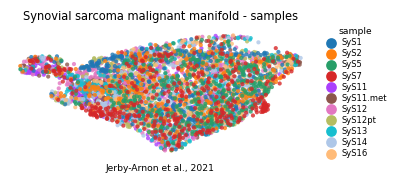

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Synovial sarcoma malignant manifold - samples', size=7.5)
ax.text(.5,-.12,'Jerby-Arnon et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])